## Load libraries

In [1]:
import polars as pl
import os
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
pl.Config.set_tbl_rows(20)  # show up to 20 rows
import polars.selectors as cs
import seaborn as sns
sns.set_style("darkgrid")  # darkgrid
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

### Read accepted_df

In [2]:
# Never use CSV again
accepted_df = pl.read_parquet("data/processed_data/eda_accepted_df.parquet")
accepted_df.head()

id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,…,revol_bal_joint,sec_app_fico_range_low,sec_app_fico_range_high,sec_app_earliest_cr_line,sec_app_inq_last_6mths,sec_app_mort_acc,sec_app_open_acc,sec_app_revol_util,sec_app_open_act_il,sec_app_num_rev_accts,sec_app_chargeoff_within_12_mths,sec_app_collections_12_mths_ex_med,sec_app_mths_since_last_major_derog,hardship_flag,hardship_type,hardship_reason,hardship_status,deferral_term,hardship_amount,hardship_start_date,hardship_end_date,payment_plan_start_date,hardship_length,hardship_dpd,hardship_loan_status,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term,target
i64,str,f64,f64,f64,str,f64,f64,str,str,str,str,str,f64,str,str,str,str,str,str,str,str,str,str,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str,str,str,f64,f64,str,f64,f64,f64,str,str,str,str,str,f64,f64,f64,i8
68407277,null,3600.0,3600.0,3600.0,""" 36 months""",13.99,123.03,"""C""","""C4""","""leadman""","""10+ years""","""MORTGAGE""",55000.0,"""Not Verified""","""Dec-2015""","""Fully Paid""","""n""","""https://lendingclub.com/browse…",null,"""debt_consolidation""","""Debt consolidation""","""190xx""","""PA""",5.91,0.0,"""Aug-2003""",675.0,679.0,1.0,30.0,null,7.0,0.0,2765.0,29.7,13.0,…,null,null,null,null,null,null,null,null,null,null,null,null,null,"""N""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""Cash""","""N""",null,null,null,null,null,null,0
68355089,null,24700.0,24700.0,24700.0,""" 36 months""",11.99,820.28,"""C""","""C1""","""Engineer""","""10+ years""","""MORTGAGE""",65000.0,"""Not Verified""","""Dec-2015""","""Fully Paid""","""n""","""https://lendingclub.com/browse…",null,"""small_business""","""Business""","""577xx""","""SD""",16.06,1.0,"""Dec-1999""",715.0,719.0,4.0,6.0,null,22.0,0.0,21470.0,19.2,38.0,…,null,null,null,null,null,null,null,null,null,null,null,null,null,"""N""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""Cash""","""N""",null,null,null,null,null,null,0
68341763,null,20000.0,20000.0,20000.0,""" 60 months""",10.78,432.66,"""B""","""B4""","""truck driver""","""10+ years""","""MORTGAGE""",63000.0,"""Not Verified""","""Dec-2015""","""Fully Paid""","""n""","""https://lendingclub.com/browse…",null,"""home_improvement""",null,"""605xx""","""IL""",10.78,0.0,"""Aug-2000""",695.0,699.0,0.0,null,null,6.0,0.0,7869.0,56.2,18.0,…,null,null,null,null,null,null,null,null,null,null,null,null,null,"""N""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""Cash""","""N""",null,null,null,null,null,null,0
68476807,null,10400.0,10400.0,10400.0,""" 60 months""",22.45,289.91,"""F""","""F1""","""Contract Specialist""","""3 years""","""MORTGAGE""",104433.0,"""Source Verified""","""Dec-2015""","""Fully Paid""","""n""","""https://lendingclub.com/browse…",null,"""major_purchase""","""Major purchase""","""174xx""","""PA""",25.37,1.0,"""Jun-1998""",695.0,699.0,3.0,12.0,null,12.0,0.0,21929.0,64.5,35.0,…,null,null,null,null,null,null,null,null,null,null,null,null,null,"""N""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""Cash""","""N""",null,null,null,null,null,null,0
68426831,null,11950.0,11950.0,11950.0,""" 36 months""",13.44,405.18,"""C""","""C3""","""Veterinary Tecnician""","""4 years""","""RENT""",34000.0,"""Source Verified""","""Dec-2015""","""Fully Paid""","""n""","""https:

In [3]:
type_summary = (
    pl.DataFrame({
        "column": accepted_df.columns,
        "dtype":  [str(accepted_df[c].dtype) for c in accepted_df.columns],
        "nulls":  [accepted_df[c].is_null().sum() for c in accepted_df.columns],
        "null_pct": [round(accepted_df[c].is_null().sum() / len(accepted_df) * 100, 2) for c in accepted_df.columns],
    })
    .sort("dtype")
)

print(f"Dataset shape: f{len(accepted_df), len(accepted_df.columns)}")
print("\n----- Null Values Distribution -----")
print(type_summary)
print()
print("\n----- Datatype Counts -----")
print(
    type_summary
    .group_by("dtype")
    .agg(pl.count().alias("n_cols"))
    .sort("n_cols", descending=True)
)


Dataset shape: f(1345310, 152)

----- Null Values Distribution -----
shape: (152, 4)
┌───────────────────────────┬─────────┬─────────┬──────────┐
│ column                    ┆ dtype   ┆ nulls   ┆ null_pct │
│ ---                       ┆ ---     ┆ ---     ┆ ---      │
│ str                       ┆ str     ┆ i64     ┆ f64      │
╞═══════════════════════════╪═════════╪═════════╪══════════╡
│ loan_amnt                 ┆ Float64 ┆ 0       ┆ 0.0      │
│ funded_amnt               ┆ Float64 ┆ 0       ┆ 0.0      │
│ funded_amnt_inv           ┆ Float64 ┆ 0       ┆ 0.0      │
│ int_rate                  ┆ Float64 ┆ 0       ┆ 0.0      │
│ installment               ┆ Float64 ┆ 0       ┆ 0.0      │
│ annual_inc                ┆ Float64 ┆ 0       ┆ 0.0      │
│ dti                       ┆ Float64 ┆ 374     ┆ 0.03     │
│ delinq_2yrs               ┆ Float64 ┆ 0       ┆ 0.0      │
│ fico_range_low            ┆ Float64 ┆ 0       ┆ 0.0      │
│ fico_range_high           ┆ Float64 ┆ 0       ┆ 0.0      │


C:\Users\Kien computer\AppData\Local\Temp\ipykernel_11152\1990453272.py:19: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  .agg(pl.count().alias("n_cols"))


In [4]:
print(accepted_df.schema)

Schema([('id', Int64), ('member_id', String), ('loan_amnt', Float64), ('funded_amnt', Float64), ('funded_amnt_inv', Float64), ('term', String), ('int_rate', Float64), ('installment', Float64), ('grade', String), ('sub_grade', String), ('emp_title', String), ('emp_length', String), ('home_ownership', String), ('annual_inc', Float64), ('verification_status', String), ('issue_d', String), ('loan_status', String), ('pymnt_plan', String), ('url', String), ('desc', String), ('purpose', String), ('title', String), ('zip_code', String), ('addr_state', String), ('dti', Float64), ('delinq_2yrs', Float64), ('earliest_cr_line', String), ('fico_range_low', Float64), ('fico_range_high', Float64), ('inq_last_6mths', Float64), ('mths_since_last_delinq', Float64), ('mths_since_last_record', Float64), ('open_acc', Float64), ('pub_rec', Float64), ('revol_bal', Float64), ('revol_util', Float64), ('total_acc', Float64), ('initial_list_status', String), ('out_prncp', Float64), ('out_prncp_inv', Float64), ('

In [5]:
null_summary = (
    accepted_df.null_count()
    .transpose(include_header=True)
    .rename({"column": "feature", "column_0": "null_count"})
    .with_columns(
        (pl.col("null_count") / accepted_df.height * 100)
        .alias("null_pct")
    )
)

cols_to_drop = (
    null_summary
    .filter(pl.col("null_pct") > 50)
    .get_column("feature")
    .to_list()
)

accepted_df = accepted_df.drop(cols_to_drop)

print(f"Dropped {len(cols_to_drop)} columns")
print(accepted_df.shape)

Dropped 58 columns
(1345310, 94)


In [6]:
# Polar String display
pl.Config.set_fmt_str_lengths(1000)

# Loan Status Distribution
print(f'Total Rows    : {accepted_df.shape[0]:,}')
print(f'Total Columns : {accepted_df.shape[1]}')
issue_d_parsed = pd.to_datetime(accepted_df['issue_d'], format='%b-%Y', errors='coerce')
print(f'Date Range    : {issue_d_parsed.min().strftime("%b-%Y")} → {issue_d_parsed.max().strftime("%b-%Y")}')

print('\n----- Loan Status Distribution -----')
print(accepted_df['loan_status'].value_counts().sort("count", descending=True))

Total Rows    : 1,345,310
Total Columns : 94
Date Range    : Jun-2007 → Dec-2018

----- Loan Status Distribution -----
shape: (2, 2)
┌─────────────┬─────────┐
│ loan_status ┆ count   │
│ ---         ┆ ---     │
│ str         ┆ u32     │
╞═════════════╪═════════╡
│ Fully Paid  ┆ 1076751 │
│ Charged Off ┆ 268559  │
└─────────────┴─────────┘


## Exp Data Analysis

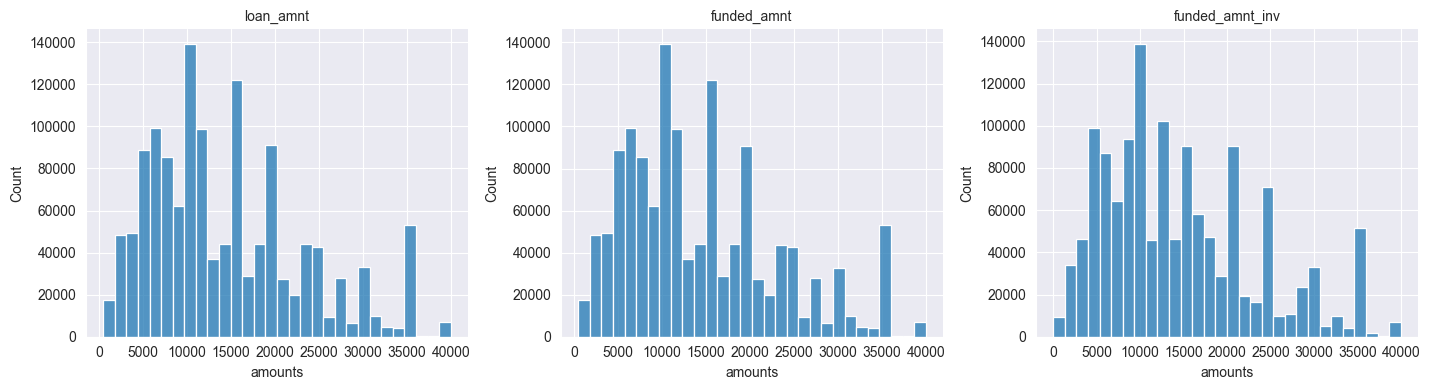

In [7]:
loan_amount_vars = [
    "loan_amnt",
    "funded_amnt",
    "funded_amnt_inv"
]

# Polars -> long format
plot_df = (
    accepted_df
    .select(loan_amount_vars)
    .unpivot(
        index=[],
        variable_name="vars",
        value_name="amounts"
    )
    .to_pandas()
)

# Faceted histograms
g = sns.FacetGrid(
    plot_df,
    col="vars",
    sharex=False,
    sharey=False,
    height=4,
    aspect=1.2
)

g.map_dataframe(
    sns.histplot,
    x="amounts",
    bins=30
)

g.set_titles("{col_name}")
plt.tight_layout()
plt.show()

High Redundancy: The three distributions (loan_amnt, funded_amnt, and funded_amnt_inv) are nearly identical. This indicates that the requested, funded, and investor-backed amounts are almost always the same, signaling high collinearity for modeling.

Psychological Pricing: The prominent spikes at $10k, $15k, $20k, and $35k show that borrowers heavily favor round numbers.

Right Skew & Hard Cap: Most loans cluster between $5k and $15k. The sharp spike and sudden drop at $35,000 indicates a strict platform lending limit.

In [8]:
# ROI
# ROI for Charged Off loans
default_roi = (
    100
    * (
        accepted_df.filter(pl.col("target") == 1)
        .select(
            (
                (pl.col("total_pymnt").sum()
                 - pl.col("funded_amnt").sum())
                / pl.col("funded_amnt").sum()
            )
        )
        .item()
    )
)

print(f"Default ROI: {default_roi:.2f}%")

# ROI for Fully Paid loans
fully_paid_roi = (
    100
    * (
        accepted_df.filter(pl.col("target") == 0)
        .select(
            (
                (pl.col("total_pymnt").sum()
                 - pl.col("funded_amnt").sum())
                / pl.col("funded_amnt").sum()
            )
        )
        .item()
    )
)

print(f"Fully Paid ROI: {fully_paid_roi:.2f}%")


Default ROI: -46.71%
Fully Paid ROI: 16.48%


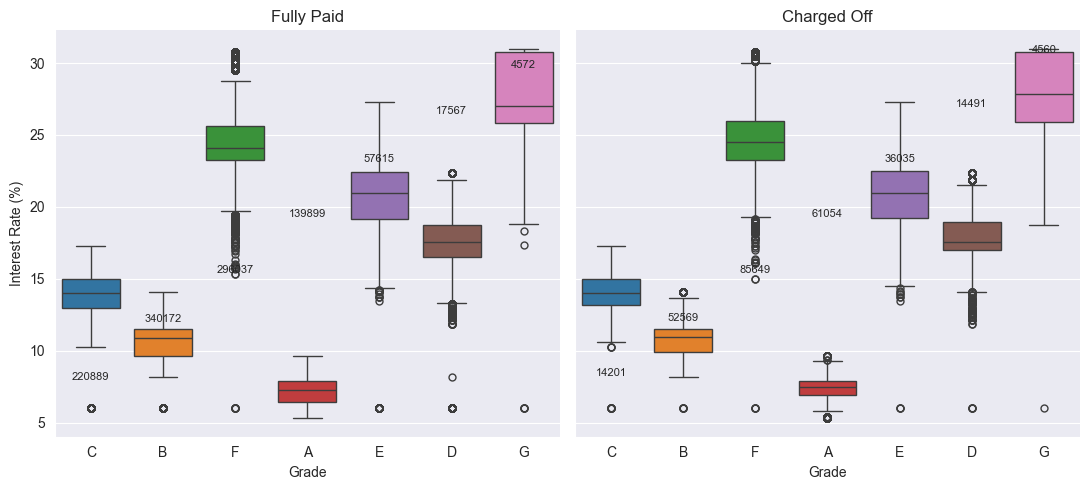

In [9]:
import polars as pl
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Convert to pandas for seaborn
plot_df = (
    accepted_df
    .select(["grade", "int_rate", "target"])
    .to_pandas()
)

# Boxplots by grade, split by target
g = sns.catplot(
    data=plot_df,
    x="grade",
    y="int_rate",
    col="target",
    kind="box",
    hue="grade",
    legend=False,
    height=5,
    aspect=1.1
)

# Add counts above each box
for ax, target_value in zip(
    g.axes.flat,
    sorted(plot_df["target"].unique())
):

    subset = plot_df[plot_df["target"] == target_value]

    counts = (
        subset
        .groupby("grade")
        .size()
        .reset_index(name="count")
    )

    for i, row in enumerate(counts.itertuples()):

        median_val = subset.loc[
            subset["grade"] == row.grade,
            "int_rate"
        ].median()

        ax.text(
            i,
            median_val * 1.1,
            str(row.count),
            ha="center",
            fontsize=8
        )

# Replace facet titles
title_map = {
    0: "Fully Paid",
    1: "Charged Off"
}

for ax, target_value in zip(
    g.axes.flat,
    sorted(plot_df["target"].unique())
):
    ax.set_title(title_map[target_value])

# Axis labels
g.set_axis_labels("Grade", "Interest Rate (%)")

plt.tight_layout()
plt.show()

Mislabeled X-Axis Order: The loan grades on the x-axis are out of alphabetical order (C, B, F, A, E, D, G).

Risk vs. Reward Pricing: When reordered logically ($A \rightarrow G$), interest rates consistently increase as the loan grade worsens. Grade A has the lowest interest rates (centered around 7%), while Grade G has the highest (centered around 28%).

Identical Rate Distributions: The interest rate distributions for each grade are virtually identical across both the Fully Paid and Charged Off categories. This means interest rate alone, within a specific grade, does not visibly distinguish defaults from successful repayments.

Higher Default Volume in Risky Grades: The numerical labels (representing sample sizes) reveal that lower grades (like E, F, and G) have a much higher proportion of "Charged Off" loans relative to their "Fully Paid" count compared to safer grades like A and B.

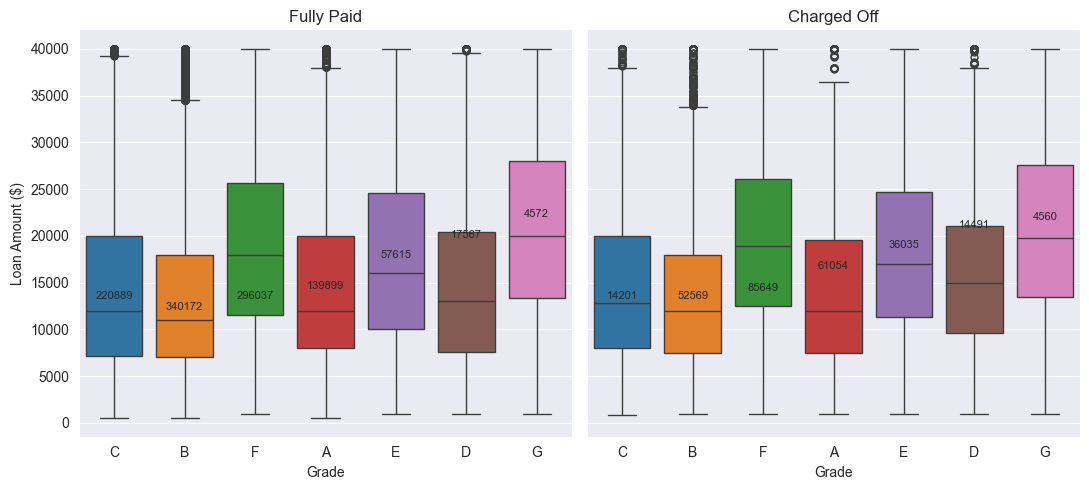

In [10]:
# Convert to pandas for seaborn
plot_df = (
    accepted_df
    .select(["grade", "loan_amnt", "target"])
    .to_pandas()
)

# Boxplots by grade, split by target
g = sns.catplot(
    data=plot_df,
    x="grade",
    y="loan_amnt",
    col="target",
    kind="box",
    hue="grade",
    legend=False,
    height=5,
    aspect=1.1
)

# Add counts above each box
for ax, target_value in zip(
    g.axes.flat,
    sorted(plot_df["target"].unique())
):

    subset = plot_df[plot_df["target"] == target_value]

    counts = (
        subset
        .groupby("grade")
        .size()
        .reset_index(name="count")
    )

    for i, row in enumerate(counts.itertuples()):

        median_val = subset.loc[
            subset["grade"] == row.grade,
            "loan_amnt"
        ].median()

        ax.text(
            i,
            median_val * 1.1,
            str(row.count),
            ha="center",
            fontsize=8
        )

# Replace facet titles
title_map = {
    0: "Fully Paid",
    1: "Charged Off"
}

for ax, target_value in zip(
    g.axes.flat,
    sorted(plot_df["target"].unique())
):
    ax.set_title(title_map[target_value])

# Axis labels
g.set_axis_labels("Grade", "Loan Amount ($)")

plt.tight_layout()
plt.show()

Unordered X-Axis: Just like the previous plot, the loan grades on the x-axis are out of alphabetical order (C, B, F, A, E, D, G).

Larger Loans for Riskier Grades: When mentally ordered from A to G, the median loan amount generally rises as the loan grade worsens. For example, Grade A loans typically center around $12,000, whereas Grade G loans center around $20,000.

Identical Distributions Across Statuses: The loan amount distributions within each individual grade look almost completely identical between Fully Paid and Charged Off borrowers. The loan size itself within a given grade does not appear to visually separate default risk.

Institutional Cap Evidence: Every single boxplot across all grades strictly caps out right at the $40,000 mark (with outliers hitting exactly $40k), further confirming a platform-wide maximum loan limit.

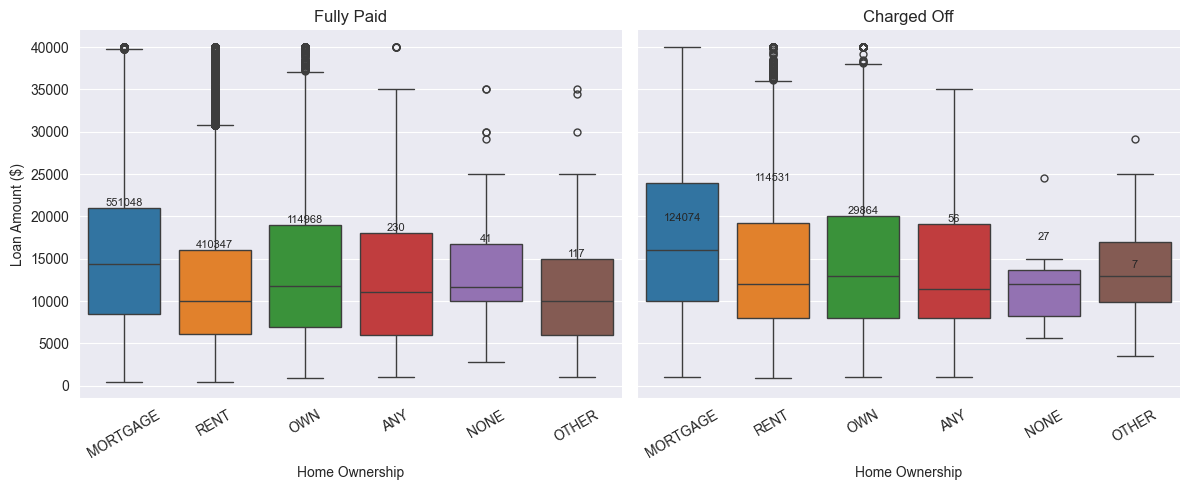

In [11]:
# Convert to pandas
plot_df = (
    accepted_df
    .select(["home_ownership", "loan_amnt", "target"])
    .to_pandas()
)

# Optional: remove missing categories
plot_df = plot_df.dropna(subset=["home_ownership"])

# Boxplots
g = sns.catplot(
    data=plot_df,
    x="home_ownership",
    y="loan_amnt",
    col="target",
    kind="box",
    hue="home_ownership",
    legend=False,
    height=5,
    aspect=1.2
)

# Add counts at 75th percentile
for ax, target_value in zip(
    g.axes.flat,
    sorted(plot_df["target"].unique())
):

    subset = plot_df[plot_df["target"] == target_value]

    counts = (
        subset
        .groupby("home_ownership")
        .size()
        .reset_index(name="count")
    )

    categories = list(
        subset["home_ownership"]
        .dropna()
        .unique()
    )

    for i, category in enumerate(categories):

        values = subset.loc[
            subset["home_ownership"] == category,
            "loan_amnt"
        ]

        q75 = values.quantile(0.75)

        count = counts.loc[
            counts["home_ownership"] == category,
            "count"
        ].iloc[0]

        ax.text(
            i,
            q75,
            str(count),
            ha="center",
            va="bottom",
            fontsize=8
        )

# Better titles
title_map = {
    0: "Fully Paid",
    1: "Charged Off"
}

for ax, target_value in zip(
    g.axes.flat,
    sorted(plot_df["target"].unique())
):
    ax.set_title(title_map[target_value])

# Labels
g.set_axis_labels(
    "Home Ownership",
    "Loan Amount ($)"
)

for ax in g.axes.flat:
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

Higher Loans for Homeowners: Borrowers with a MORTGAGE take out noticeably larger loans (median around $15,000–$16,000) compared to those who RENT or have OTHER/NONE housing statuses (medians around $10,000–$12,000).

Slightly Higher Loan Amounts in Defaults: Across the primary categories (MORTGAGE, RENT, OWN), the median loan amounts are slightly higher in the Charged Off group than in the Fully Paid group, suggesting larger loan sizes lean marginally riskier.

Massive Sample Size Imbalance: The numeric labels reveal that MORTGAGE and RENT dominate the dataset (hundreds of thousands of loans), while categories like ANY, NONE, and OTHER have extremely small, statistically negligible sample sizes (e.g., as few as 7 to 56 loans in the default group).

Consistent Upper Cap: The institutional maximum loan ceiling remains visible across all major ownership types, maxing out cleanly near the $40,000 line.

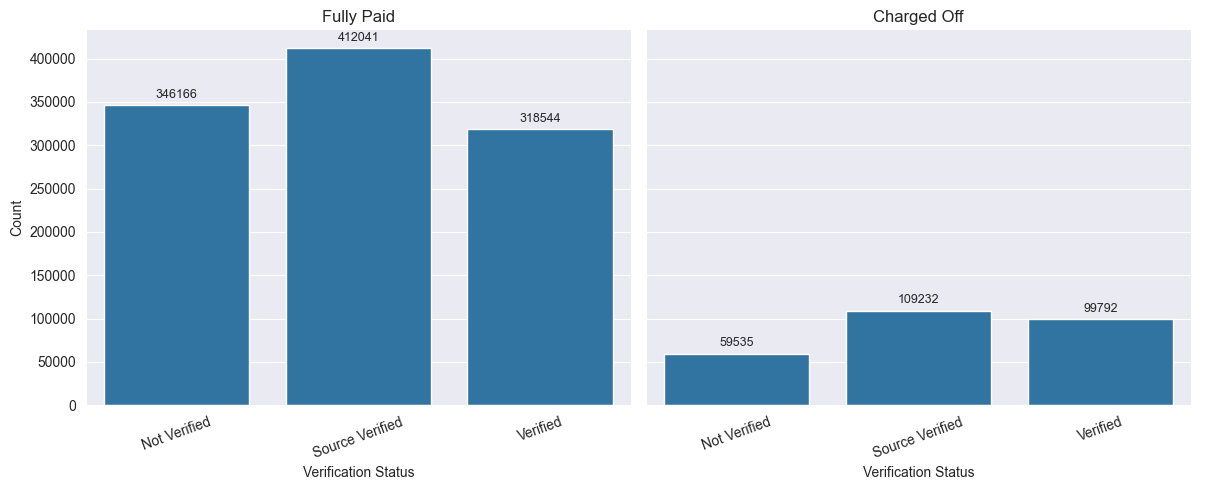

In [12]:
# Convert to pandas
plot_df = (
    accepted_df
    .select(["verification_status", "target"])
    .to_pandas()
)

# Bar chart with facets
g = sns.catplot(
    data=plot_df,
    x="verification_status",
    col="target",
    kind="count",
    height=5,
    aspect=1.2
)

# Add counts above bars
for ax in g.axes.flat:

    for container in ax.containers:

        labels = [
            f"{int(bar.get_height())}"
            for bar in container
        ]

        ax.bar_label(
            container,
            labels=labels,
            padding=3,
            fontsize=9
        )

# Replace facet titles
title_map = {
    0: "Fully Paid",
    1: "Charged Off"
}

for ax, target_value in zip(
    g.axes.flat,
    sorted(plot_df["target"].unique())
):
    ax.set_title(title_map[target_value])

# Labels
g.set_axis_labels(
    "Verification Status",
    "Count"
)

# Rotate labels if needed
for ax in g.axes.flat:
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

Higher Default Rates for Verified Income: Counterintuitively, loans that are Verified or Source Verified show a higher proportion of defaults compared to Not Verified loans. For instance, roughly 24% of Verified loans end up charged off ($99,792 / [318,544 + 99,792]$), compared to only about 15% for Not Verified loans ($59,535 / [346,166 + 59,535]$).

Confounding Variable Likely: This paradox usually occurs because lenders only mandate income verification for riskier, larger loan applications, while letting safer, lower-amount borrowers pass through unverified.

Volume Distribution: The Source Verified category holds the largest total volume of loans across both the Fully Paid and Charged Off statuses, closely followed by Not Verified and Verified.

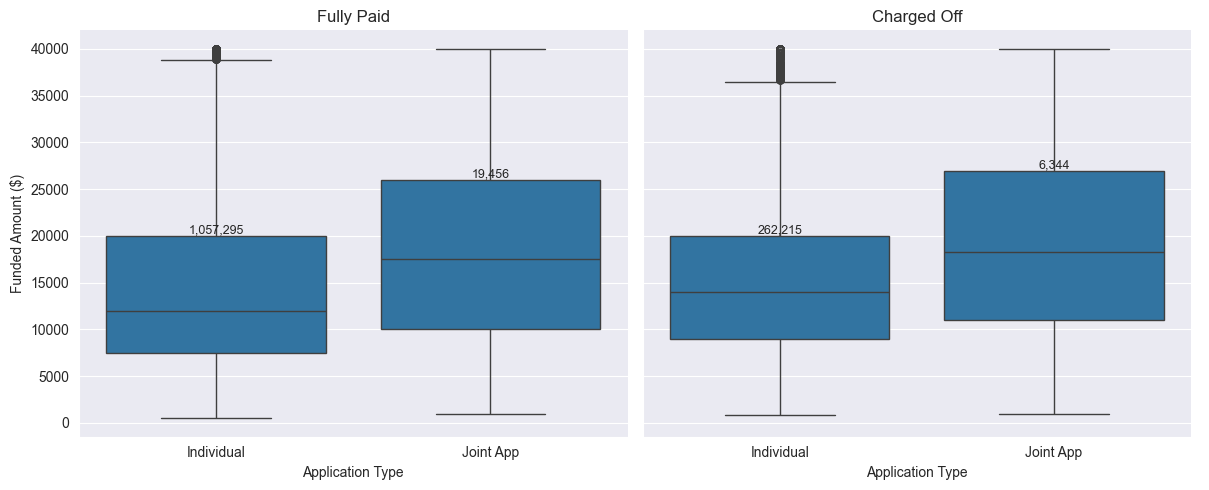

In [13]:
# Convert to pandas
plot_df = (
    accepted_df
    .select(["application_type", "funded_amnt", "target"])
    .to_pandas()
)

# Remove missing values if any
plot_df = plot_df.dropna(subset=["application_type"])

# Boxplots
g = sns.catplot(
    data=plot_df,
    x="application_type",
    y="funded_amnt",
    col="target",
    kind="box",
    height=5,
    aspect=1.2
)

# Add counts at 75th percentile (Q3)
for ax, target_value in zip(
    g.axes.flat,
    sorted(plot_df["target"].unique())
):

    subset = plot_df[plot_df["target"] == target_value]

    counts = (
        subset
        .groupby("application_type")
        .size()
        .reset_index(name="count")
    )

    categories = list(subset["application_type"].unique())

    for i, category in enumerate(categories):

        values = subset.loc[
            subset["application_type"] == category,
            "funded_amnt"
        ]

        q75 = values.quantile(0.75)

        count = counts.loc[
            counts["application_type"] == category,
            "count"
        ].iloc[0]

        ax.text(
            i,
            q75,
            f"{count:,}",
            ha="center",
            va="bottom",
            fontsize=9
        )

# Replace facet titles
title_map = {
    0: "Fully Paid",
    1: "Charged Off"
}

for ax, target_value in zip(
    g.axes.flat,
    sorted(plot_df["target"].unique())
):
    ax.set_title(title_map[target_value])

# Labels
g.set_axis_labels(
    "Application Type",
    "Funded Amount ($)"
)

plt.tight_layout()
plt.show()

Larger Funding for Joint Applications: Borrowers using a Joint App receive noticeably higher funded amounts (median around $17,500–$18,000) than those applying as an Individual (median around $12,000–$14,000). This suggests multiple incomes allow for larger loan approvals.

Higher Default Risk with Larger Individual Loans: For Individual applicants, the median funded amount is visually higher in the Charged Off category than the Fully Paid category, indicating that larger solo loans carry higher default risk.

Massive Imbalance in Sample Volume: Individual applications overwhelmingly dominate the dataset, with over 1.3 million total loans (1,057,295 paid vs. 262,215 charged off). Joint applications represent a tiny fraction of the portfolio by comparison.

Higher Proportion of Defaults for Joint Applications: Looking at the sample labels, about 24.6% of Joint App loans end up charged off ($\approx 6,344 / 25,800$), compared to roughly 19.9% for Individual loans ($\approx 262,215 / 1,319,510$).

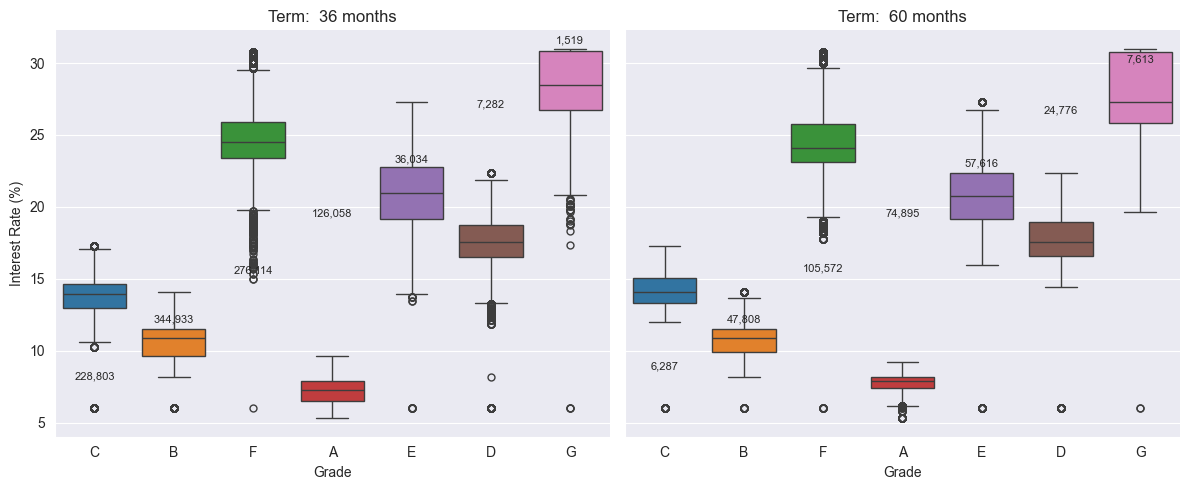

In [14]:
# Convert to pandas
plot_df = (
    accepted_df
    .select(["grade", "int_rate", "term"])
    .to_pandas()
)

# Boxplots by grade, split by term
g = sns.catplot(
    data=plot_df,
    x="grade",
    y="int_rate",
    col="term",
    kind="box",
    hue="grade",
    legend=False,
    height=5,
    aspect=1.2
)

# Add counts above each box
for ax, term_value in zip(
    g.axes.flat,
    sorted(plot_df["term"].unique())
):

    subset = plot_df[plot_df["term"] == term_value]

    counts = (
        subset
        .groupby("grade")
        .size()
        .reset_index(name="count")
    )

    grade_order = sorted(
        subset["grade"].dropna().unique()
    )

    for i, grade in enumerate(grade_order):

        values = subset.loc[
            subset["grade"] == grade,
            "int_rate"
        ]

        if len(values) == 0:
            continue

        median_val = values.median()

        count = counts.loc[
            counts["grade"] == grade,
            "count"
        ].iloc[0]

        ax.text(
            i,
            median_val * 1.1,
            f"{count:,}",
            ha="center",
            fontsize=8
        )

# Better titles
for ax, term_value in zip(
    g.axes.flat,
    sorted(plot_df["term"].unique())
):
    ax.set_title(f"Term: {term_value}")

# Axis labels
g.set_axis_labels(
    "Grade",
    "Interest Rate (%)"
)

plt.tight_layout()
plt.show()

Consistent Mislabeled X-Axis: The loan grades on the x-axis repeat the out-of-order sequence (C, B, F, A, E, D, G) observed in prior charts.

Term Length Dictates Grade Volume: Shorter-term loans (36 months) heavily dominate safer grades (e.g., Grade B has 344,933 loans vs. just 47,808 in the 60-month term). Conversely, riskier grades shift noticeably toward longer-term loans (60 months) (e.g., Grade G has 7,613 loans vs. only 1,519 in the 36-month term).

Identical Interest Rates Across Terms: For any given grade, the interest rate distribution (median, quartiles, and range) remains practically identical whether the loan term is 36 months or 60 months.

Risk-Based Pricing Preserved: When reordered alphabetically from A to G, interest rates climb steadily across both terms—ranging from roughly 7% for Grade A up to nearly 28% for Grade G

NameError: name 'StrMethodFormatter' is not defined

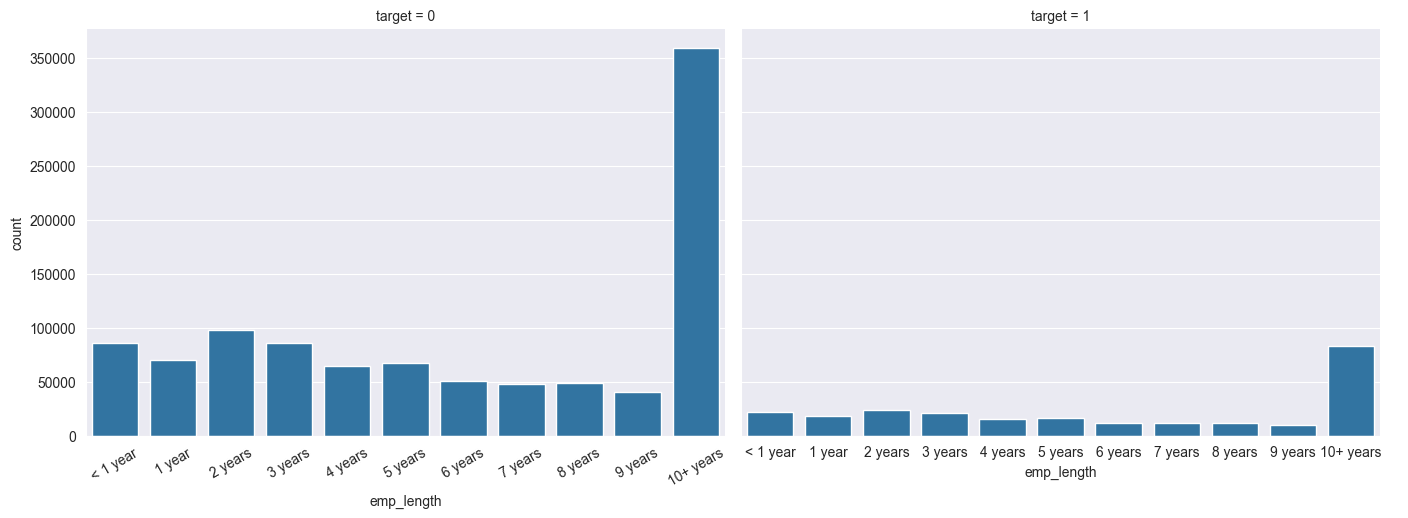

In [15]:
# Convert to pandas
plot_df = (
    accepted_df
    .select(["emp_length", "target"])
    .to_pandas()
)

# Optional: order employment lengths logically
emp_order = [
    "< 1 year",
    "1 year",
    "2 years",
    "3 years",
    "4 years",
    "5 years",
    "6 years",
    "7 years",
    "8 years",
    "9 years",
    "10+ years"
]

# Keep only values that exist
emp_order = [x for x in emp_order if x in plot_df["emp_length"].unique()]

# Faceted count plots
g = sns.catplot(
    data=plot_df,
    x="emp_length",
    col="target",
    kind="count",
    order=emp_order,
    height=5,
    aspect=1.4
)

# Format y-axis and rotate labels
for ax in g.axes.flat:

    ax.tick_params(
        axis="x",
        rotation=30
    )

    ax.yaxis.set_major_formatter(
        StrMethodFormatter("{x:,.0f}")
    )

# Replace facet titles
title_map = {
    0: "Fully Paid",
    1: "Charged Off"
}

for ax, target_value in zip(
    g.axes.flat,
    sorted(plot_df["target"].unique())
):
    ax.set_title(title_map[target_value])

# Axis labels
g.set_axis_labels(
    "Employment Length",
    "Number of Loans"
)

plt.tight_layout()
plt.show()

Dominance of Long-Term Employment: Borrowers with 10+ years of employment length overwhelmingly dominate the dataset, making up the vast majority of loans in both the "Fully Paid" (over 350,000) and "Charged Off" (around 80,000) groups.

Uniform Distribution for 1–9 Years: For employment lengths between < 1 year and 9 years, the loan volume remains relatively stable and evenly distributed, hovering under the 100,000 mark for paid loans and under 25,000 for defaults.

Constant Default Rate Across Lengths: The proportion of defaults relative to fully paid loans is highly consistent across every single category. Regardless of whether a borrower has < 1 year or 10+ years of experience, roughly 15% to 20% of the loans in each category end up charged off, suggesting that employment length alone is a weak predictor of default risk.

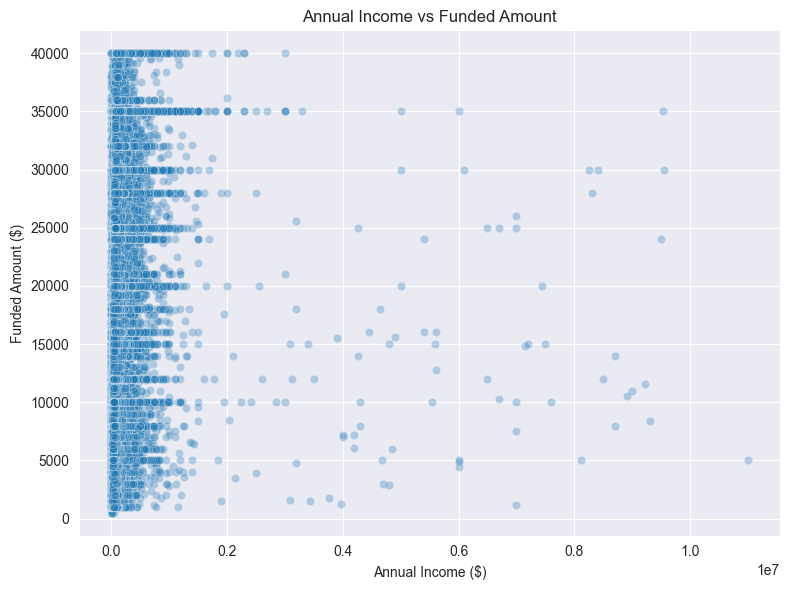

In [ ]:

plot_df = (
    accepted_df
    .select(["annual_inc", "funded_amnt"])
    .drop_nulls()
    .to_pandas()
)

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=plot_df,
    x="annual_inc",
    y="funded_amnt",
    alpha=0.3
)

plt.xlabel("Annual Income ($)")
plt.ylabel("Funded Amount ($)")
plt.title("Annual Income vs Funded Amount")

plt.tight_layout()
plt.show()

Extreme Income Outliers: The x-axis scale extends up to $1.0 \times 10^7$ ($10 million), indicating the presence of extreme high-income outliers that heavily skew the visualization.

Heavy Concentration at Lower Incomes: The vast majority of data points are densely compressed in a vertical column close to $0 on the left side of the chart, showing that most borrowers earn a fraction of the maximum income displayed.

Visible $35k and $40k Hard Caps: Horizontal stripes of data points appear noticeably at $35,000 and $40,000, reconfirming strict institutional loan limits regardless of how much money a borrower makes.

Weak Linear Correlation: Outside of the tight clustering on the left, the scattered data points suggest a weak or nonexistent direct linear correlation between annual income and the funded amount. High-income earners do not automatically receive higher funded amounts due to the hard cap.

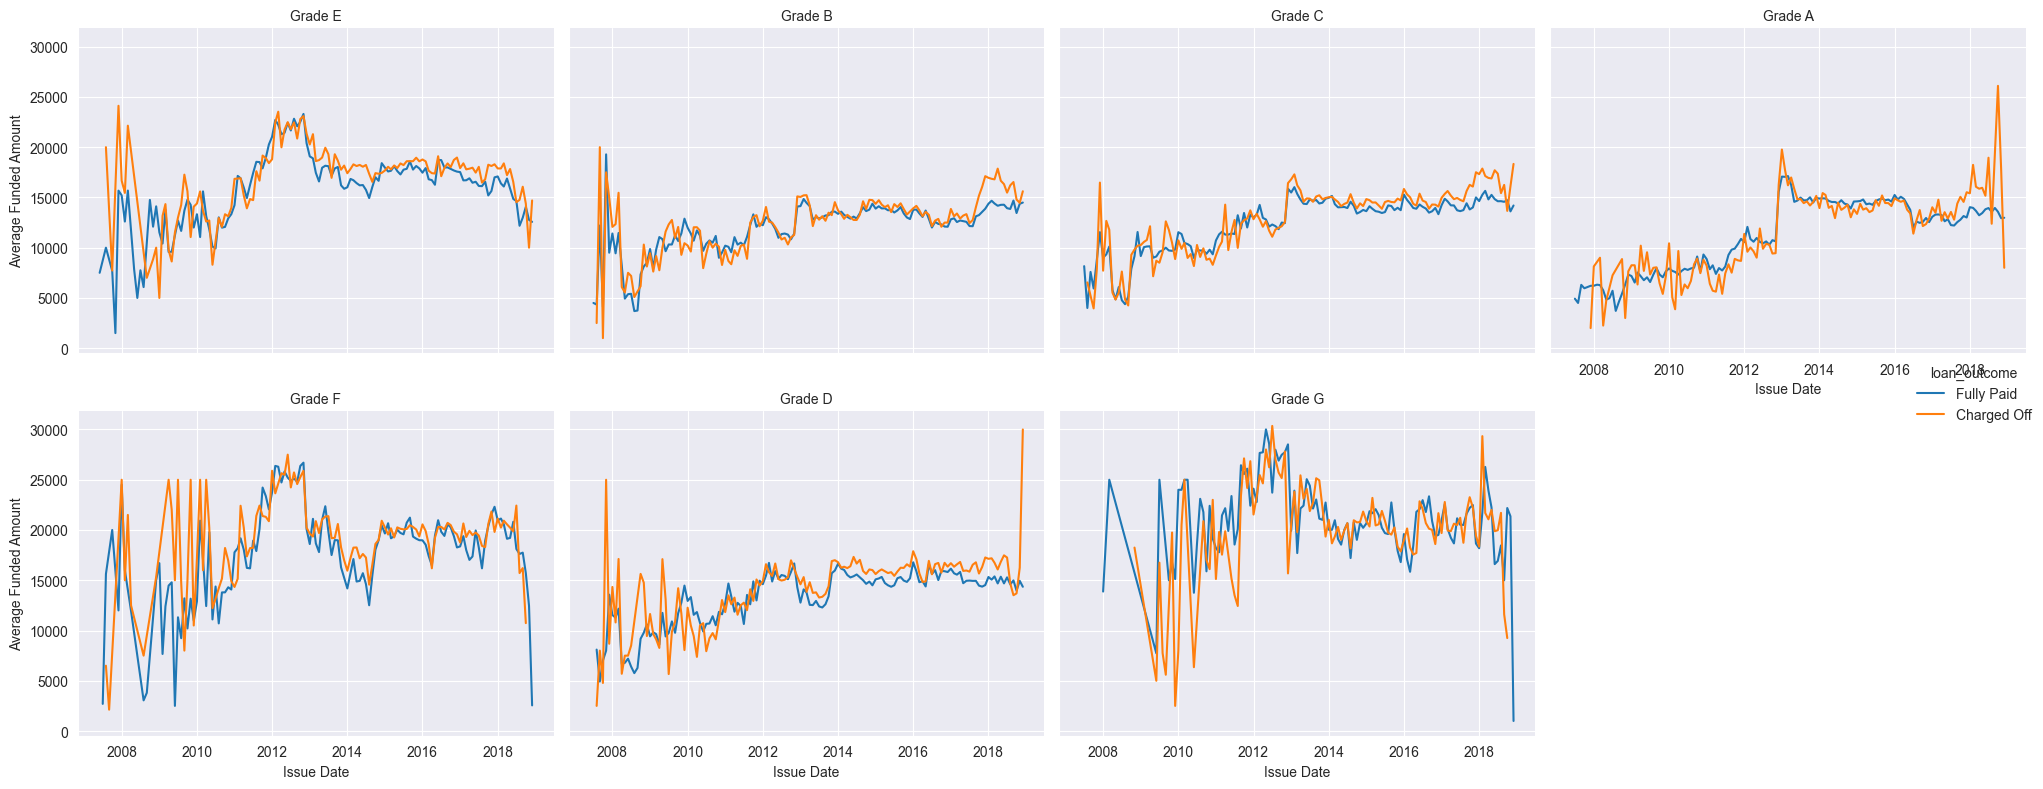

In [ ]:


# Parse issue_d
plot_df = (
    accepted_df
    .with_columns(
        pl.col("issue_d")
        .str.strptime(pl.Date, "%b-%Y", strict=False)
        .alias("issue_dt")
    )
    .group_by(["grade", "target", "issue_dt"])
    .agg(
        pl.col("funded_amnt")
        .mean()
        .alias("funded_amount")
    )
    .sort("issue_dt")
    .to_pandas()
)

# Rename target labels
plot_df["loan_outcome"] = (
    plot_df["target"]
    .map({
        0: "Fully Paid",
        1: "Charged Off"
    })
)

# Faceted line plots
g = sns.relplot(
    data=plot_df,
    x="issue_dt",
    y="funded_amount",
    hue="loan_outcome",
    col="grade",
    col_wrap=4,
    kind="line",
    linewidth=1.5,
    height=4,
    aspect=1.2
)

g.set_axis_labels(
    "Issue Date",
    "Average Funded Amount"
)

g.set_titles("Grade {col_name}")

plt.tight_layout()
plt.show()

Upward Trend Over Time: Across all loan grades, the average funded amount has generally trended upward from 2008 through 2019, reflecting loan price inflation or increasing maximum caps on the platform over the years.

Higher Defaults for Larger Loans: Within almost every sub-plot, the orange line (Charged Off) frequently tracks slightly above the blue line (Fully Paid), showing that defaults consistently correlate with a higher average funded amount over time.

Extreme Volatility in Early Years: The period between 2008 and 2011 shows intense, erratic spikes and drops for both metrics, likely caused by low overall loan volume (small sample sizes) on the platform during its infancy.

Volatility Correlates with Risk: The riskier loan grades (Grade E, F, and G) display significantly more jagged, volatile lines throughout the timeline compared to the much smoother, highly stable trajectories of safer categories like Grade A, B, and C.

In [ ]:
accepted_df = accepted_df.with_columns(
    pl.when((pl.col("dti") >= 0) & (pl.col("dti") <= 10))
      .then(pl.lit("dti_0-10"))

    .when((pl.col("dti") > 10) & (pl.col("dti") <= 20))
      .then(pl.lit("dti_10-20"))

    .when((pl.col("dti") > 20) & (pl.col("dti") <= 30))
      .then(pl.lit("dti_20-30"))

    .when((pl.col("dti") > 30) & (pl.col("dti") <= 40))
      .then(pl.lit("dti_30-40"))

    .when((pl.col("dti") > 40) & (pl.col("dti") <= 50))
      .then(pl.lit("dti_40-50"))

    .when((pl.col("dti") > 50) & (pl.col("dti") <= 60))
      .then(pl.lit("dti_50-60"))

    .when((pl.col("dti") > 60) & (pl.col("dti") <= 70))
      .then(pl.lit("dti_60-70"))

    .when((pl.col("dti") > 70) & (pl.col("dti") <= 80))
      .then(pl.lit("dti_70-80"))

    .when((pl.col("dti") > 80) & (pl.col("dti") <= 90))
      .then(pl.lit("dti_80-90"))

    .when((pl.col("dti") > 90) & (pl.col("dti") <= 100))
      .then(pl.lit("dti_90-100"))

    .when(pl.col("dti") > 100)
      .then(pl.lit("dti_100"))

    .otherwise(None)
    .alias("dti_range_100")
)

dti_summary = (
    accepted_df
    .group_by("dti_range_100")
    .len()
    .sort("dti_range_100")
)

print(dti_summary)

shape: (12, 2)
┌───────────────┬────────┐
│ dti_range_100 ┆ len    │
│ ---           ┆ ---    │
│ str           ┆ u32    │
╞═══════════════╪════════╡
│ null          ┆ 376    │
│ dti_0-10      ┆ 246177 │
│ dti_10-20     ┆ 562111 │
│ dti_100       ┆ 533    │
│ dti_20-30     ┆ 408347 │
│ dti_30-40     ┆ 121533 │
│ dti_40-50     ┆ 3992   │
│ dti_50-60     ┆ 1060   │
│ dti_60-70     ┆ 559    │
│ dti_70-80     ┆ 320    │
│ dti_80-90     ┆ 184    │
│ dti_90-100    ┆ 118    │
└───────────────┴────────┘


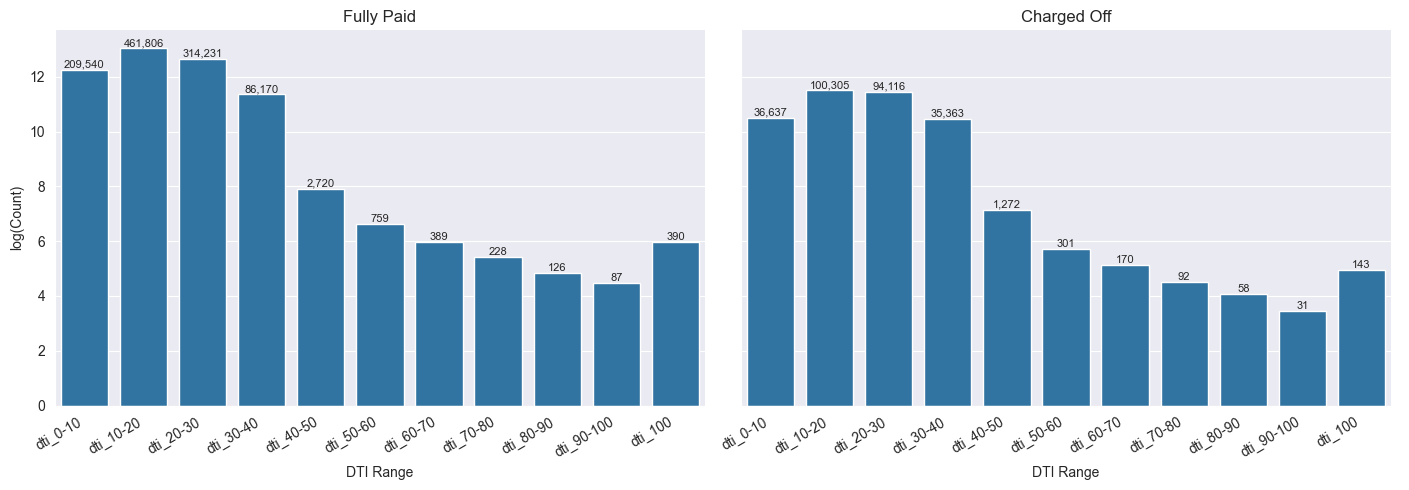

In [ ]:
plot_df = (
    accepted_df
    .group_by(["dti_range_100", "target"])
    .len()
    .with_columns(
        pl.col("len")
        .cast(pl.Float64)
        .log()
        .alias("log_count")
    )
    .to_pandas()
)

# Order categories
dti_order = [
    "dti_0-10",
    "dti_10-20",
    "dti_20-30",
    "dti_30-40",
    "dti_40-50",
    "dti_50-60",
    "dti_60-70",
    "dti_70-80",
    "dti_80-90",
    "dti_90-100",
    "dti_100"
]

g = sns.catplot(
    data=plot_df,
    x="dti_range_100",
    y="log_count",
    col="target",
    kind="bar",
    order=dti_order,
    height=5,
    aspect=1.4
)

# Add original counts on top
for ax, target_value in zip(
    g.axes.flat,
    sorted(plot_df["target"].unique())
):

    subset = plot_df[plot_df["target"] == target_value]

    for i, row in enumerate(
        subset.set_index("dti_range_100")
              .reindex(dti_order)
              .dropna()
              .itertuples()
    ):
        ax.text(
            i,
            row.log_count,
            f"{int(row.len):,}",
            ha="center",
            va="bottom",
            fontsize=8
        )

# Better titles
title_map = {
    0: "Fully Paid",
    1: "Charged Off"
}

for ax, target_value in zip(
    g.axes.flat,
    sorted(plot_df["target"].unique())
):
    ax.set_title(title_map[target_value])

# Rotate labels
for ax in g.axes.flat:
    plt.setp(
        ax.get_xticklabels(),
        rotation=30,
        ha="right"
    )

g.set_axis_labels(
    "DTI Range",
    "log(Count)"
)

plt.tight_layout()
plt.show()

In [ ]:
# -----------------------------
# Numeric variables
# -----------------------------
numeric_vars = [
    col
    for col, dtype in accepted_df.schema.items()
    if dtype.is_numeric()
]

# Remove variables not treated as continuous
numeric_vars = [
    col
    for col in numeric_vars
    if col not in [
        "id",
        "member_id",
        "policy_code",
        "dti",
        "delinq_2yrs"
    ]
]

# -----------------------------
# Outlier treatment (IQR capping)
# -----------------------------
treated_cols = []

for col in numeric_vars:

    q1 = accepted_df.select(
        pl.col(col).quantile(0.25)
    ).item()

    q3 = accepted_df.select(
        pl.col(col).quantile(0.75)
    ).item()

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    treated_cols.append(
        pl.when(pl.col(col) < lower)
          .then(pl.lit(lower))
          .when(pl.col(col) > upper)
          .then(pl.lit(upper))
          .otherwise(pl.col(col))
          .alias(col)
    )

# Apply outlier treatment
loan_num_vars = (
    accepted_df
    .select(treated_cols)
    .unpivot(
        variable_name="measure",
        value_name="values"
    )
)

print(loan_num_vars.head())

shape: (5, 2)
┌───────────┬─────────┐
│ measure   ┆ values  │
│ ---       ┆ ---     │
│ str       ┆ f64     │
╞═══════════╪═════════╡
│ loan_amnt ┆ 3600.0  │
│ loan_amnt ┆ 24700.0 │
│ loan_amnt ┆ 20000.0 │
│ loan_amnt ┆ 10400.0 │
│ loan_amnt ┆ 11950.0 │
└───────────┴─────────┘


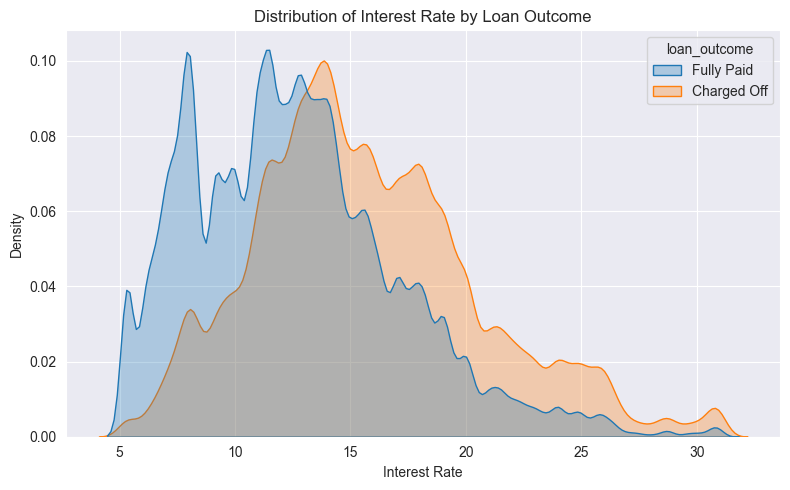

In [ ]:
plot_df = (
    accepted_df
    .select(["int_rate", "target"])
    .drop_nulls()
    .to_pandas()
)

plot_df["loan_outcome"] = (
    plot_df["target"]
    .map({
        0: "Fully Paid",
        1: "Charged Off"
    })
)

plt.figure(figsize=(8, 5))

sns.kdeplot(
    data=plot_df,
    x="int_rate",
    hue="loan_outcome",
    fill=True,
    alpha=0.3,
    common_norm=False
)

plt.xlabel("Interest Rate")
plt.ylabel("Density")
plt.title("Distribution of Interest Rate by Loan Outcome")

plt.tight_layout()
plt.show()

Higher Rates Correlate with Defaults: The distribution for Charged Off loans (orange) is visibly shifted to the right compared to Fully Paid loans (blue), showing that higher interest rates strongly correlate with a greater likelihood of default.

Distinct Peak Locations: The peak density for successful repayments (Fully Paid) is concentrated at lower interest rates between roughly 7% and 12%, whereas the peak density for defaults (Charged Off) sits higher, centered around 14% to 15%.

Clear Risk Threshold: Below approximately 12%, the density of fully paid loans heavily dominates. Above 13%, the density of charged-off loans becomes proportionally much larger, emphasizing that risk scales rapidly with higher pricing.

Multimodal Spikes: Both curves exhibit multiple smaller peaks and ridges throughout the distribution, indicating that the platform assigns interest rates at specific fixed tiers or brackets rather than on a perfectly continuous scale.

In [ ]:
palette = {'Fully Paid': '#2ecc71', 'Charged Off': '#e74c3c'}

# Convert to pandas
plot_df = accepted_df.select(['loan_amnt', 'int_rate', 'grade', 'target']).to_pandas()
plot_df['label'] = plot_df['target'].map({0: 'Fully Paid', 1: 'Charged Off'})

# Grade default rate, converted to Pandas
grade_default = (
    accepted_df
    .group_by('grade')
    .agg(pl.col('target').mean().alias('default_rate'))
    .sort('grade')
    .to_pandas()
)

C:\Users\Kien computer\AppData\Local\Temp\ipykernel_17452\4235072824.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


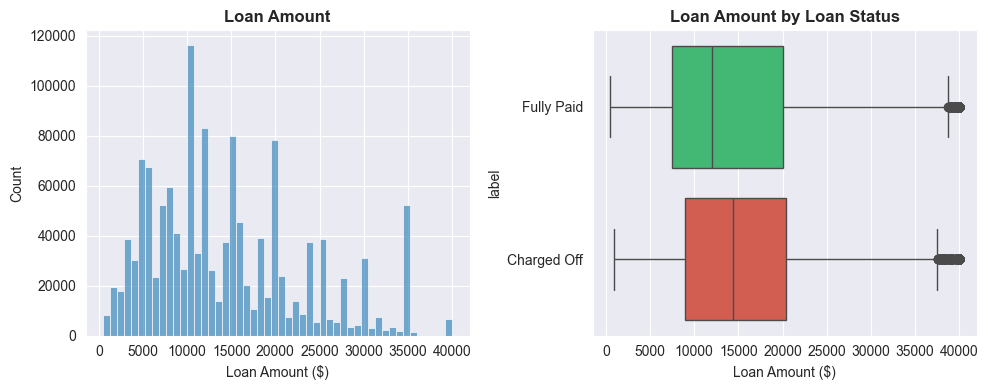

In [ ]:
# Loan amount histogram and boxplot
fig1, ax1 = plt.subplots(1, 2, figsize=(10, 4))

sns.histplot(
    data=plot_df, x='loan_amnt',
    bins=50, alpha=0.6, ax=ax1[0]
)
ax1[0].set_title('Loan Amount', fontweight='bold')
ax1[0].set_xlabel('Loan Amount ($)')
ax1[0].set_ylabel('Count')

sns.boxplot(
    data=plot_df, x='loan_amnt', y='label',
    palette=palette, ax=ax1[1], legend=False
)
ax1[1].set_title('Loan Amount by Loan Status', fontweight='bold')
ax1[1].set_xlabel('Loan Amount ($)')

plt.tight_layout()
plt.show()


C:\Users\Kien computer\AppData\Local\Temp\ipykernel_17452\73350079.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


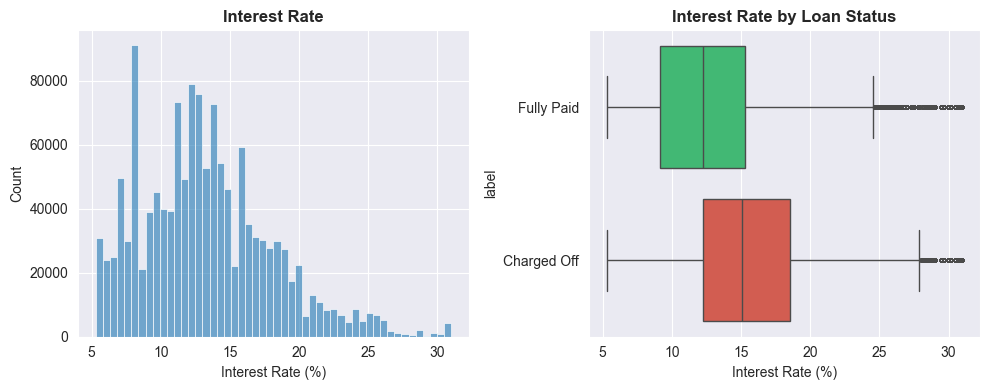

In [ ]:
# Interest rate histogram and boxplot
fig2, ax2 = plt.subplots(1, 2, figsize=(10, 4))

sns.histplot(
    data=plot_df, x='int_rate',
    bins=50, alpha=0.6, ax=ax2[0]
)
ax2[0].set_title('Interest Rate', fontweight='bold')
ax2[0].set_xlabel('Interest Rate (%)')
ax2[0].set_ylabel('Count')

sns.boxplot(
    data=plot_df, x='int_rate', y='label',
    palette=palette, ax=ax2[1], legend=False,
    flierprops=dict(marker='o', markersize=2, alpha=0.3)
)
ax2[1].set_title('Interest Rate by Loan Status', fontweight='bold')
ax2[1].set_xlabel('Interest Rate (%)')

plt.tight_layout()
plt.show()

C:\Users\Kien computer\AppData\Local\Temp\ipykernel_17452\4151115882.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


FileNotFoundError: [Errno 2] No such file or directory: '../img/default_rate_by_grade.png'

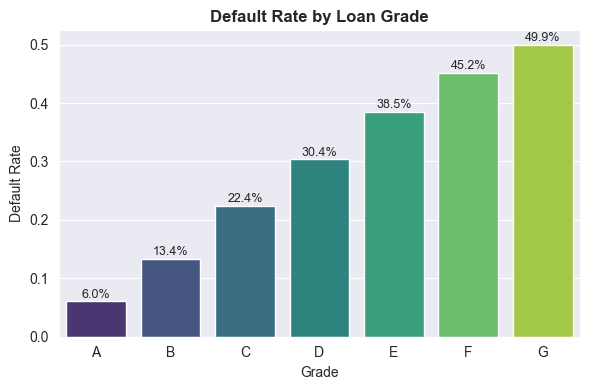

In [ ]:
# Default Rate by Loan Grade
fig3, ax = plt.subplots(figsize=(6, 4))

sns.barplot(
    data=grade_default, x='grade', y='default_rate',
    palette='viridis', ax=ax
)
ax.set_title('Default Rate by Loan Grade', fontweight='bold')
ax.set_xlabel('Grade')
ax.set_ylabel('Default Rate')

for bar, (_, row) in zip(ax.patches, grade_default.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.001,
        f"{row['default_rate']*100:.1f}%",
        ha='center', va='bottom', fontsize=9
    )

plt.tight_layout()
plt.show()

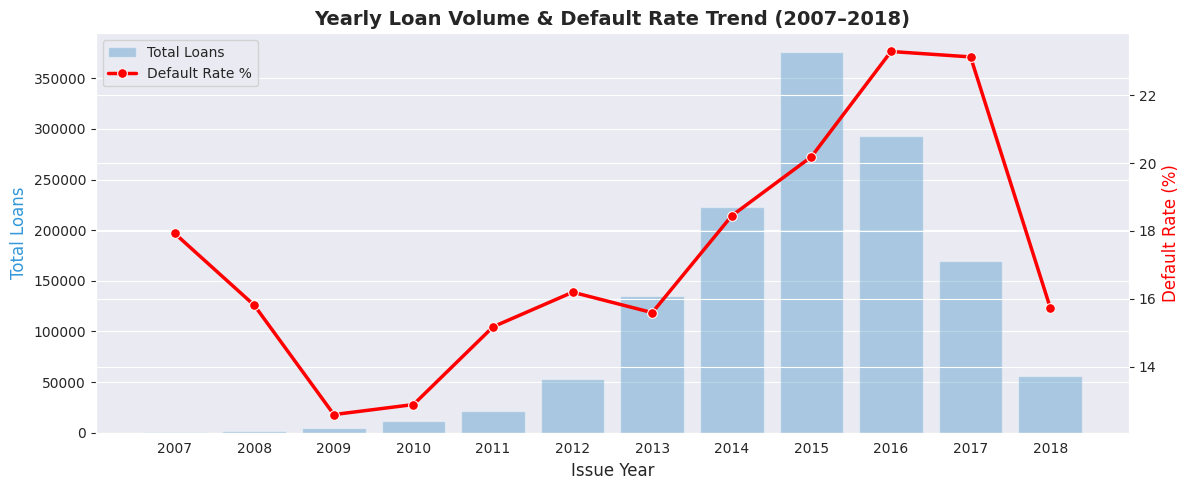

In [ ]:
# Calculate yearly numbers of loan and default statuses
yearly = (
    accepted_df
    .with_columns(
        pl.col("issue_d")
          .str.to_date(format="%b-%Y")
          .dt.year()
          .alias("issue_year")
    )
    .group_by("issue_year")
    .agg([
        pl.col("target").count().alias("total_loans"),
        pl.col("target").sum().alias("defaults")
    ])
    .with_columns(
        (pl.col("defaults") / pl.col("total_loans") * 100).alias("default_rate")
    )
    .sort("issue_year")
    .to_pandas()
)


# Convert year to string so bars spread across x-axis
yearly["issue_year"] = yearly["issue_year"].astype(str)

fig, ax1 = plt.subplots(figsize=(12, 5))
ax2 = ax1.twinx()

# Plot: total loans on ax1
sns.barplot(
    data=yearly,
    x="issue_year",
    y="total_loans",
    alpha=0.4,
    color="#3498db",
    label="Total Loans",
    ax=ax1
)

# Plot: default rate on ax2
sns.lineplot(
    data=yearly,
    x="issue_year",
    y="default_rate",
    color="red",
    linewidth=2.5,
    marker="o",
    markersize=7,
    label="Default Rate %",
    ax=ax2
)

# Labels
ax1.set_xlabel("Issue Year", fontsize=12)
ax1.set_ylabel("Total Loans", fontsize=12, color="#3498db")
ax2.set_ylabel("Default Rate (%)", fontsize=12, color="red")

# Fix 2: remove ax2's auto legend before merging
ax2.get_legend().remove()

# Combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

plt.title("Yearly Loan Volume & Default Rate Trend (2007–2018)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### emp_length
emp_length: Employment length in years. Possible values are between 0 and 10 where 0 means less than one year and 10 means ten or more years.
$\rightarrow$ Replace $(<1, 0)$, $(10+, 10)$, and remove null rows

Text(0, 0.5, 'Charge Off Rate (%)')

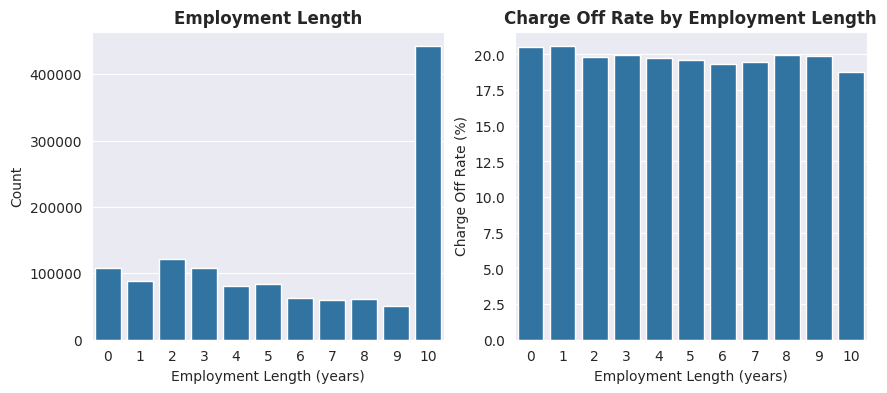

In [ ]:
# Compute charge off rate by emp_length
emp_default = (
    accepted_df 
    .group_by("emp_length")
    .agg([
        pl.col("target").sum().alias("charged_off"),
        pl.len().alias("total")
    ])
    .with_columns(
        (pl.col("charged_off") / pl.col("total") * 100).alias("chargeoff_rate")
    )
    .sort("emp_length")
    .to_pandas()
)

plot_emp = accepted_df.select(["emp_length", "target"]).to_pandas()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Left: count plot
sns.countplot(
    data=plot_emp,
    x="emp_length",
    ax=axes[0]
)
axes[0].set_title("Employment Length", fontweight="bold")
axes[0].set_xlabel("Employment Length (years)")
axes[0].set_ylabel("Count")

# Right: charge off rate
sns.barplot(
    data=emp_default,
    x="emp_length",
    y="chargeoff_rate",
    ax=axes[1]
)
axes[1].set_title("Charge Off Rate by Employment Length", fontweight="bold")
axes[1].set_xlabel("Employment Length (years)")
axes[1].set_ylabel("Charge Off Rate (%)")

# Save fig
plt.tight_layout()
plt.show()

### home_ownership
home_ownership: The home ownership status provided by the borrower.

Values: RENT, OWN, MORTGAGE, OTHER

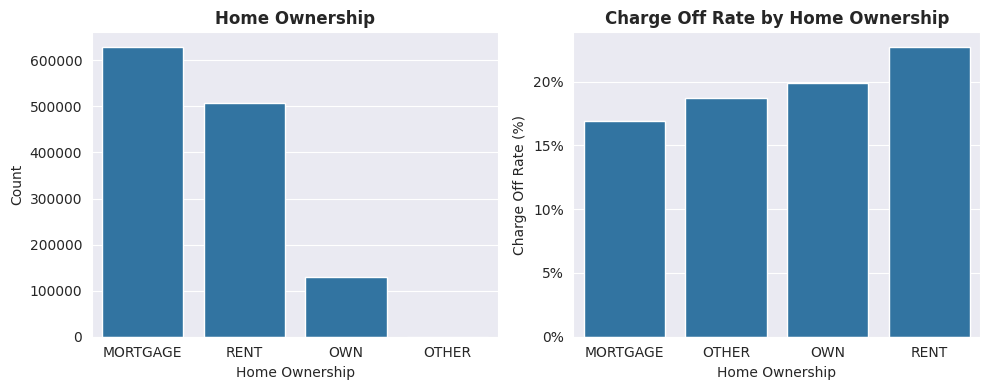

In [ ]:
# Before visualization
home_default = (
    accepted_df 
    .group_by("home_ownership")
    .agg([
        pl.col("target").sum().alias("charged_off"),
        pl.len().alias("total")
    ])
    .with_columns(
        (pl.col("charged_off") / pl.col("total") * 100).alias("chargeoff_rate")
    )
    .sort("home_ownership")
    .to_pandas()
)

plot_home = accepted_df .select(["home_ownership", "target"]).to_pandas()

# Plot
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.countplot(data=plot_home, x="home_ownership", ax=axes[0])
axes[0].set_title("Home Ownership", fontweight="bold")
axes[0].set_xlabel("Home Ownership")
axes[0].set_ylabel("Count")

sns.barplot(data=home_default, x="home_ownership", y="chargeoff_rate", ax=axes[1])
axes[1].set_title("Charge Off Rate by Home Ownership", fontweight="bold")
axes[1].set_xlabel("Home Ownership")
axes[1].set_ylabel("Charge Off Rate (%)")
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x:.0f}%'))

plt.tight_layout()
plt.show()

### verification_status

verification_status: Indicates if income was verified by LendingClub.

Values: Verified, Source Verified, Not Verified

shape: (3, 2)
┌─────────────────────┬────────┐
│ verification_status ┆ count  │
│ ---                 ┆ ---    │
│ str                 ┆ u32    │
╞═════════════════════╪════════╡
│ Source Verified     ┆ 506114 │
│ Not Verified        ┆ 389913 │
│ Verified            ┆ 370772 │
└─────────────────────┴────────┘


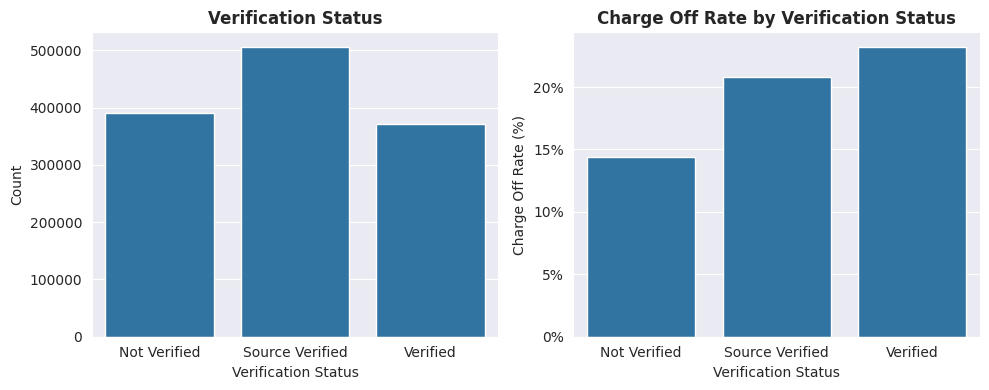

In [ ]:
vfi_default = (
    accepted_df
    .group_by("verification_status")
    .agg([
        pl.col("target").sum().alias("charged_off"),
        pl.len().alias("total")
    ])
    .with_columns(
        (pl.col("charged_off") / pl.col("total") * 100).alias("chargeoff_rate")
    )
    .sort("verification_status")
    .to_pandas()
)

plot_vfi = accepted_df.select(["verification_status", "target"]).to_pandas()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.countplot(data=plot_vfi, x="verification_status", ax=axes[0])
axes[0].set_title("Verification Status", fontweight="bold")
axes[0].set_xlabel("Verification Status")
axes[0].set_ylabel("Count")

sns.barplot(data=vfi_default, x="verification_status", y="chargeoff_rate", ax=axes[1])
axes[1].set_title("Charge Off Rate by Verification Status", fontweight="bold")
axes[1].set_xlabel("Verification Status")
axes[1].set_ylabel("Charge Off Rate (%)")
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x:.0f}%'))

plt.tight_layout()
plt.show()

### pub_rec_bankcruptcies

In [ ]:
bktc_default = (
    accepted_df
    .group_by("pub_rec_bankruptcies")
    .agg([
        pl.col("target").sum().alias("charged_off"),
        pl.len().alias("total")
    ])
    .with_columns(
        (pl.col("charged_off") / pl.col("total") * 100).alias("chargeoff_rate")
    )
    .sort("chargeoff_rate", descending=True)
    .to_pandas()
)

plot_bktc = accepted_df.select(["pub_rec_bankruptcies", "target"]).to_pandas()
bktc_order = sorted(bktc_default["pub_rec_bankruptcies"].tolist())

shape: (12, 2)
┌──────────────────────┬─────────┐
│ pub_rec_bankruptcies ┆ count   │
│ ---                  ┆ ---     │
│ f64                  ┆ u32     │
╞══════════════════════╪═════════╡
│ 0.0                  ┆ 1114316 │
│ 1.0                  ┆ 142623  │
│ 2.0                  ┆ 7139    │
│ 3.0                  ┆ 1461    │
│ 4.0                  ┆ 361     │
│ 5.0                  ┆ 133     │
│ 6.0                  ┆ 42      │
│ 7.0                  ┆ 14      │
│ 8.0                  ┆ 8       │
│ 9.0                  ┆ 3       │
│ 11.0                 ┆ 1       │
│ 12.0                 ┆ 1       │
└──────────────────────┴─────────┘


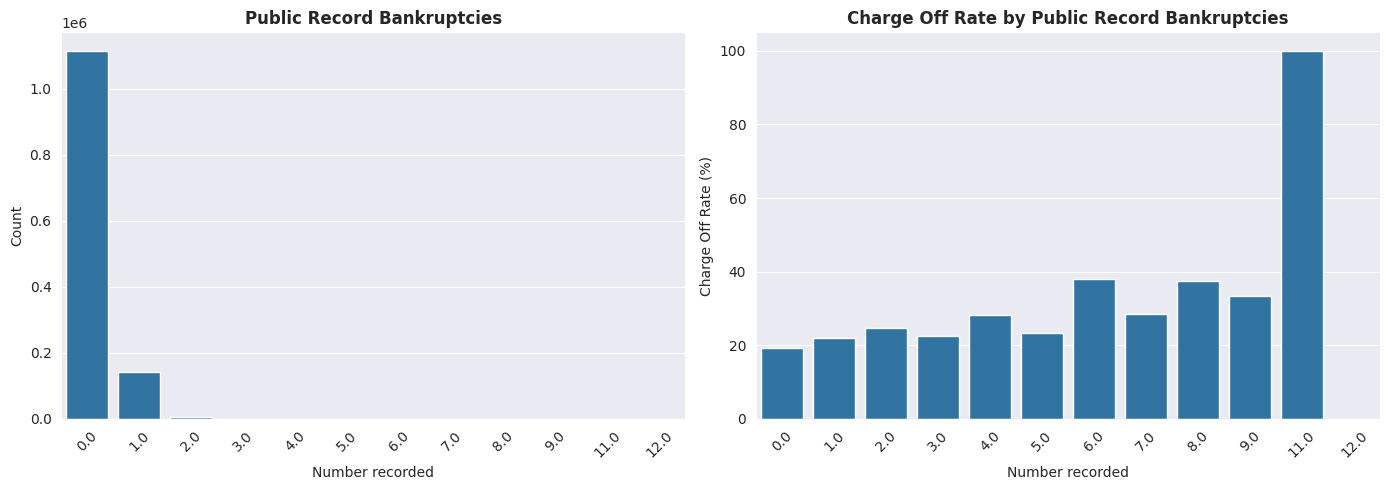

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=plot_bktc, x="pub_rec_bankruptcies", order=bktc_order, ax=axes[0])
axes[0].set_title("Public Record Bankruptcies", fontweight="bold")
axes[0].set_xlabel("Number recorded")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis="x", rotation=45)

sns.barplot(data=bktc_default, x="pub_rec_bankruptcies", y="chargeoff_rate",
            order=bktc_order, ax=axes[1])
axes[1].set_title("Charge Off Rate by Public Record Bankruptcies", fontweight="bold")
axes[1].set_xlabel("Number recorded")
axes[1].set_ylabel("Charge Off Rate (%)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### purpose
purpose: A category provided by the borrower for the loan request.

Values: debt_consolidation, credit_card, home_improvement, etc.

In [ ]:
purpose_default = (
    accepted_df
    .group_by("purpose")
    .agg([
        pl.col("target").sum().alias("charged_off"),
        pl.len().alias("total")
    ])
    .with_columns(
        (pl.col("charged_off") / pl.col("total") * 100).alias("chargeoff_rate")
    )
    .sort("chargeoff_rate", descending=True)
    .to_pandas()
)

plot_purpose = accepted_df.select(["purpose", "target"]).to_pandas()
purpose_order = sorted(purpose_default["purpose"].tolist())

shape: (14, 2)
┌────────────────────┬────────┐
│ purpose            ┆ count  │
│ ---                ┆ ---    │
│ str                ┆ u32    │
╞════════════════════╪════════╡
│ debt_consolidation ┆ 737280 │
│ credit_card        ┆ 277310 │
│ home_improvement   ┆ 81205  │
│ other              ┆ 72144  │
│ major_purchase     ┆ 27754  │
│ small_business     ┆ 14924  │
│ medical            ┆ 14244  │
│ car                ┆ 13763  │
│ moving             ┆ 8875   │
│ vacation           ┆ 8366   │
│ house              ┆ 6818   │
│ wedding            ┆ 2243   │
│ renewable_energy   ┆ 876    │
│ educational        ┆ 300    │
└────────────────────┴────────┘


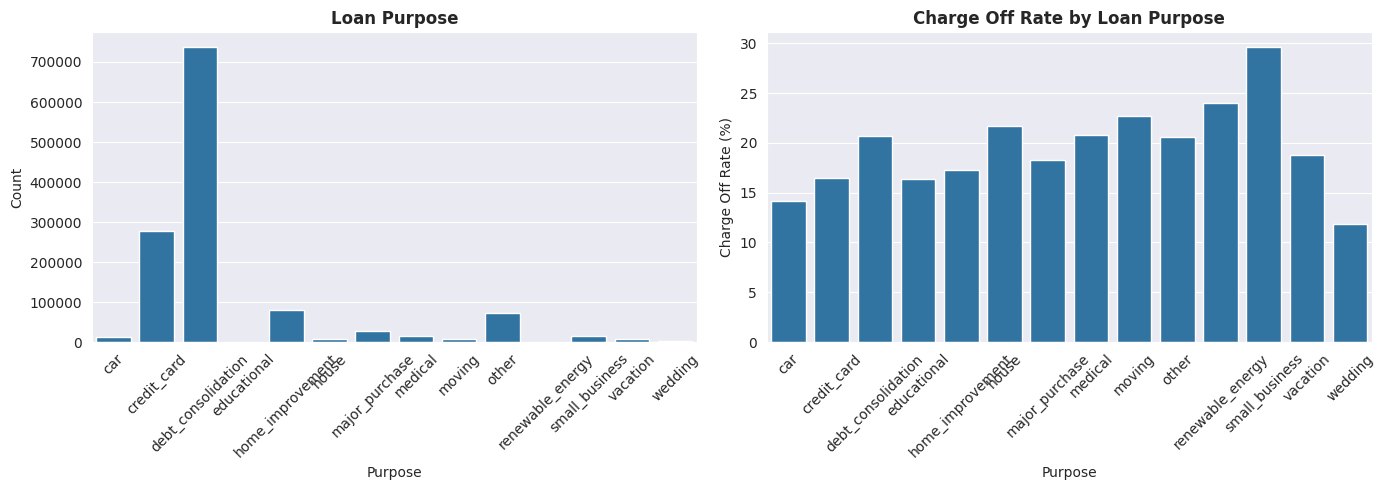

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=plot_purpose, x="purpose", order=purpose_order, ax=axes[0])
axes[0].set_title("Loan Purpose", fontweight="bold")
axes[0].set_xlabel("Purpose")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis="x", rotation=45)

sns.barplot(data=purpose_default, x="purpose", y="chargeoff_rate",
            order=purpose_order, ax=axes[1])
axes[1].set_title("Charge Off Rate by Loan Purpose", fontweight="bold")
axes[1].set_xlabel("Purpose")
axes[1].set_ylabel("Charge Off Rate (%)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### annual_inc

annual_inc: The self-reported annual income provided by the borrower.

shape: (9, 2)
┌────────────┬──────────────┐
│ statistic  ┆ value        │
│ ---        ┆ ---          │
│ str        ┆ f64          │
╞════════════╪══════════════╡
│ count      ┆ 1.266102e6   │
│ null_count ┆ 0.0          │
│ mean       ┆ 77904.067011 │
│ std        ┆ 71068.992023 │
│ min        ┆ 0.0          │
│ 25%        ┆ 48000.0      │
│ 50%        ┆ 65000.0      │
│ 75%        ┆ 92555.0      │
│ max        ┆ 1.09992e7    │
└────────────┴──────────────┘


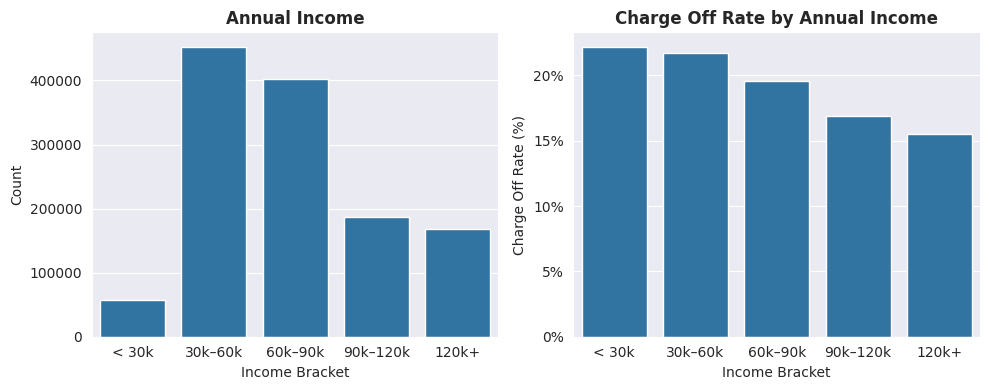

In [ ]:
bracket_order = ["< 30k", "30k–60k", "60k–90k", "90k–120k", "120k+"]

inc_default = (
    accepted_df
    .group_by("income_bracket")
    .agg([
        pl.col("target").sum().alias("charged_off"),
        pl.len().alias("total")
    ])
    .with_columns(
        (pl.col("charged_off") / pl.col("total") * 100).alias("chargeoff_rate")
    )
    .to_pandas()
)
inc_default["income_bracket"] = pd.Categorical(inc_default["income_bracket"],
                                                categories=bracket_order, ordered=True)
inc_default = inc_default.sort_values("income_bracket")

plot_inc = accepted_df.select(["income_bracket", "target"]).to_pandas()
plot_inc["income_bracket"] = pd.Categorical(plot_inc["income_bracket"],
                                             categories=bracket_order, ordered=True)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.countplot(data=plot_inc, x="income_bracket", order=bracket_order, ax=axes[0])
axes[0].set_title("Annual Income", fontweight="bold")
axes[0].set_xlabel("Income Bracket")
axes[0].set_ylabel("Count")

sns.barplot(data=inc_default, x="income_bracket", y="chargeoff_rate",
            order=bracket_order, ax=axes[1])
axes[1].set_title("Charge Off Rate by Annual Income", fontweight="bold")
axes[1].set_xlabel("Income Bracket")
axes[1].set_ylabel("Charge Off Rate (%)")
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x:.0f}%'))

plt.tight_layout()
plt.show()

### annual_inc × purpose
Examine how charge off rate varies across income brackets within each loan purpose

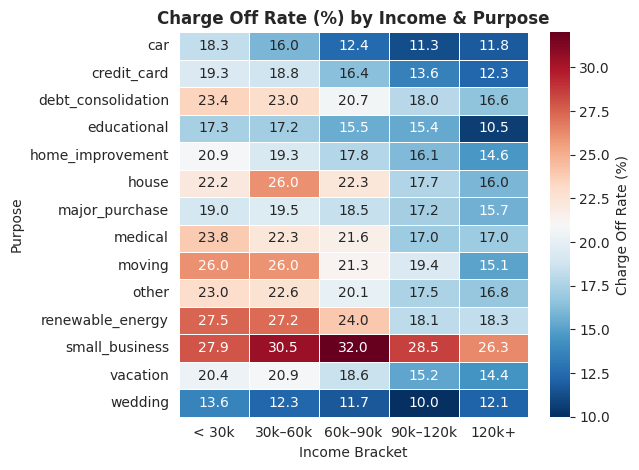

In [ ]:
combo = (
    accepted_df
    .group_by(["income_bracket", "purpose"])
    .agg([
        pl.col("target").sum().alias("charged_off"),
        pl.len().alias("total")
    ])
    .with_columns(
        (pl.col("charged_off") / pl.col("total") * 100).alias("chargeoff_rate")
    )
    .to_pandas()
)

combo["income_bracket"] = pd.Categorical(combo["income_bracket"],
                                          categories=bracket_order, ordered=True)
combo = combo.sort_values(["purpose", "income_bracket"])

# charge off rate heatmap (income bracket vs purpose)
heatmap_df = combo.pivot(index="purpose", columns="income_bracket", values="chargeoff_rate")
heatmap_df = heatmap_df[bracket_order]  # enforce column order

sns.heatmap(
    heatmap_df,
    annot=True,
    fmt=".1f",
    cmap="RdBu_r",
    linewidths=0.5,
    cbar_kws={"label": "Charge Off Rate (%)"}
)
plt.title("Charge Off Rate (%) by Income & Purpose", fontweight="bold")
plt.xlabel("Income Bracket")
plt.ylabel("Purpose")
plt.tight_layout()
plt.show()

### Debt-to-income_ratio

In [ ]:
dti_loan = accepted_df.select(["target", "dti", "grade"]).to_pandas()
dti_loan.groupby("target")["dti"].describe()

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,1018777.0,17.683830,9.453260,-1.0,11.41,17.04,23.32,999.0
1,247308.0,19.981591,9.821457,0.0,13.50,19.66,26.15,999.0


/tmp/ipykernel_41393/1641291474.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


(0.0, 100.0)

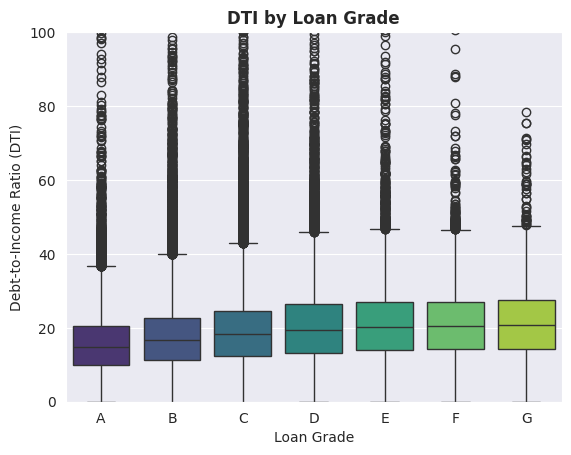

In [ ]:
sns.boxplot(
    data=dti_loan,
    x="grade",
    y="dti",
    order=sorted(plot_df["grade"].dropna().unique()),
    palette="viridis",
)
plt.title("DTI by Loan Grade", fontweight="bold")
plt.xlabel("Loan Grade")
plt.ylabel("Debt-to-Income Ratio (DTI)")
plt.ylim(0, 100)

### mort_acc
mort_acc: Number of mortgage accounts

**Insight: **Individuals who pay off their loans are more likely to have several mortgage accounts.

In [ ]:
mort_accounts = accepted_df.select(["target", "mort_acc"]).to_pandas()
mort_accounts.groupby("target")["mort_acc"].describe()

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,980033.0,1.737275,2.030610,0.0,0.0,1.0,3.0,51.0
1,240825.0,1.361275,1.818124,0.0,0.0,1.0,2.0,29.0


Individuals who pay off their loans are more likely to have several mortgage accounts.